In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
dataset = load_digits()

In [ ]:
X = dataset.data
y = dataset.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
model = Sequential([
    Input(shape=(64,)),
    Dense(16, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax'),
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=25, batch_size=32, validation_split=0.1, verbose=1)
model.summary()

Epoch 1/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.1036 - loss: 3.4807 - val_accuracy: 0.1667 - val_loss: 2.2327
Epoch 2/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2521 - loss: 2.0889 - val_accuracy: 0.3194 - val_loss: 1.9867
Epoch 3/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4401 - loss: 1.8325 - val_accuracy: 0.4653 - val_loss: 1.8142
Epoch 4/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5267 - loss: 1.5937 - val_accuracy: 0.5139 - val_loss: 1.5744
Epoch 5/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6025 - loss: 1.3220 - val_accuracy: 0.6458 - val_loss: 1.2200
Epoch 6/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6852 - loss: 1.0208 - val_accuracy: 0.7431 - val_loss: 0.9021
Epoch 7/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7517 - loss: 0.7771 - val_accuracy: 0.7847 - val_loss: 0.7170
Epoch 8/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8036 - loss: 0.6238 - val_accuracy: 0.8194 - val_loss

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_46 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,744 (22.44 KB)

 Trainable params: 1,914 (7.48 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,830 (14.96 KB)

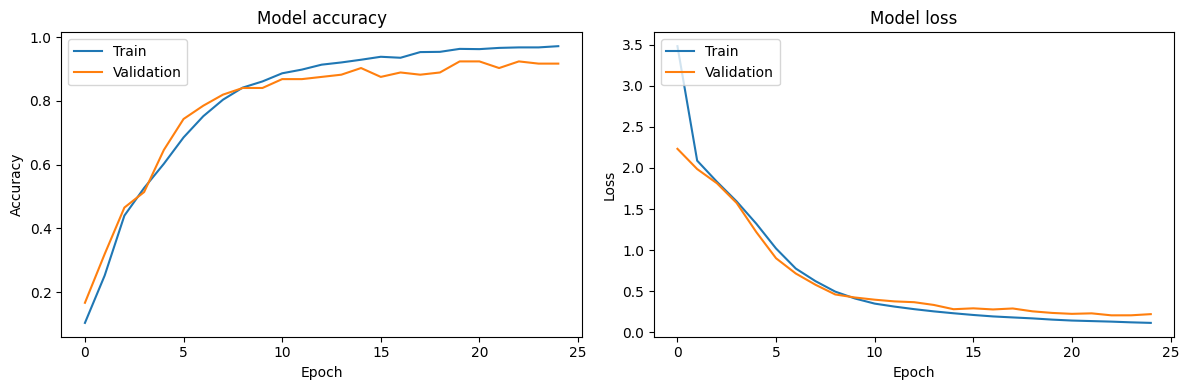

In [ ]:
# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

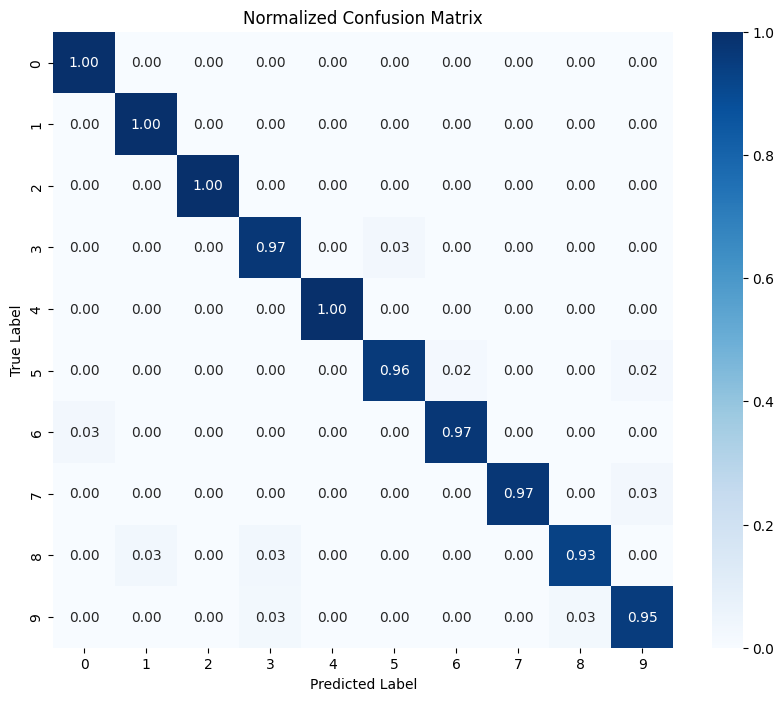

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Compute normalized confusion matrix
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues')
plt.title('Normalized Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Print a detailed report to quantify the analysis
print("Detailed Performance Metrics:")
print(classification_report(y_test, np.argmax(model.predict(X_test), axis=1)))

Detailed Performance Metrics:
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
              precision    recall  f1-score   support

           0       1.00      0.91      0.95        33
           1       0.88      0.82      0.85        28
           2       0.97      0.94      0.95        33
           3       1.00      0.94      0.97        34
           4       0.96      1.00      0.98        46
           5       0.93      0.91      0.92        47
           6       0.97      1.00      0.99        35
           7       1.00      0.97      0.99        34
           8       0.70      0.87      0.78        30
           9       0.85      0.85      0.85        40

    accuracy                           0.93       360
   macro avg       0.93      0.92      0.92       360
weighted avg       0.93      0.93      0.93       360



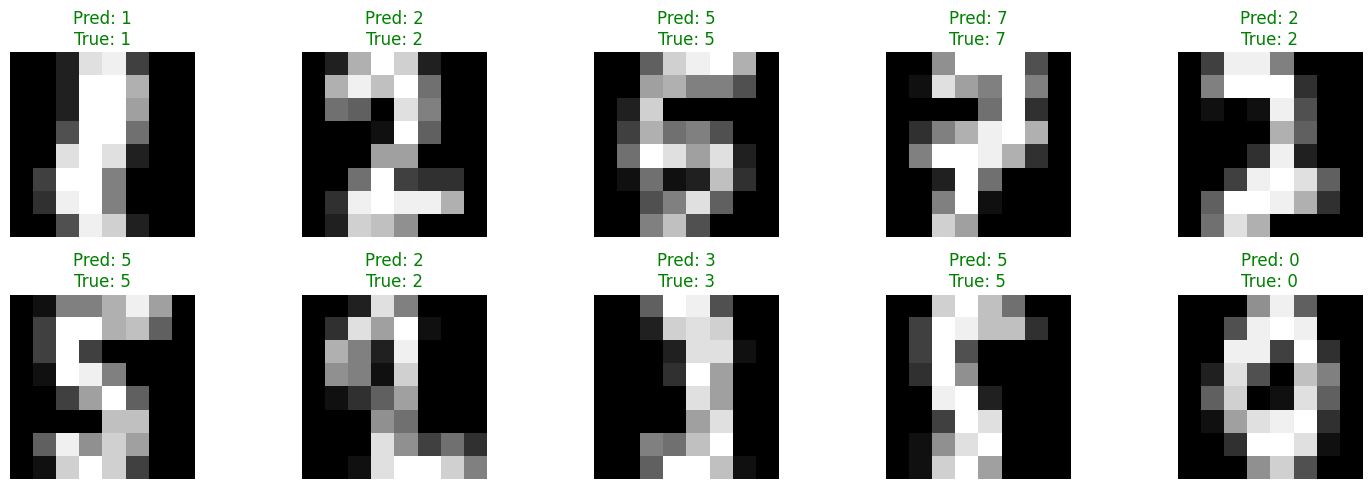

In [ ]:
random_indices = np.random.choice(len(X_test), size=10, replace=False)
sample_images = X_test[random_indices]
sample_labels = y_test[random_indices]
predictions = y_pred[random_indices]

plt.figure(figsize=(15, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i].reshape(8, 8), cmap='gray')
    title_color = 'green' if predictions[i] == sample_labels[i] else 'red'
    plt.title(f"Pred: {predictions[i]}\nTrue: {sample_labels[i]}", color=title_color)
    plt.axis('off')

plt.tight_layout()
plt.show()

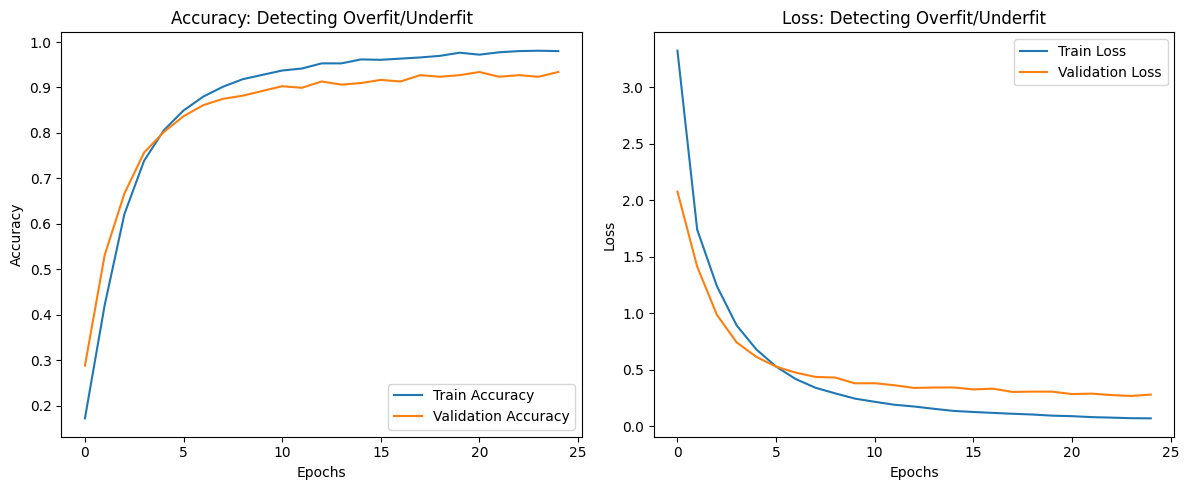

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy: Detecting Overfit/Underfit')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss: Detecting Overfit/Underfit')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step


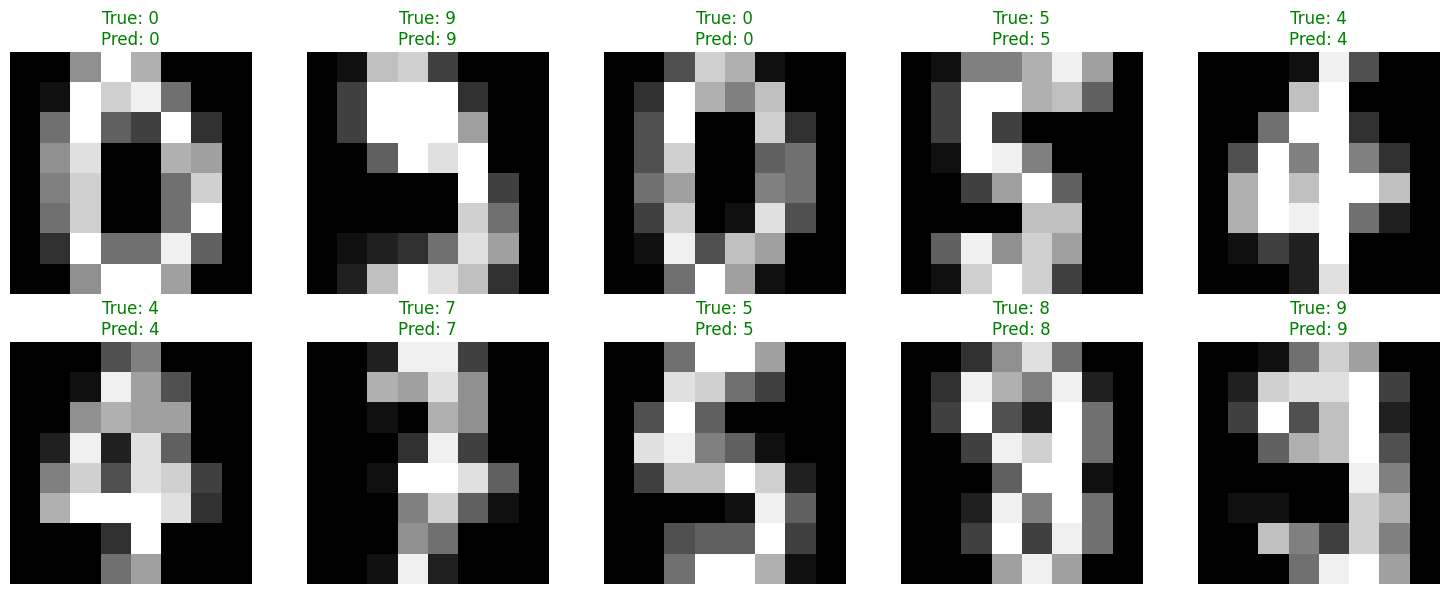

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Select 10 random indices from the test set
indices = np.random.choice(len(X_test), 10, replace=False)
sample_images = X_test[indices]
sample_labels = y_test[indices]

# Make predictions
predictions = model.predict(sample_images)
predicted_labels = np.argmax(predictions, axis=1)

# Plot the results
plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i].reshape(8, 8), cmap='gray')
    color = 'green' if predicted_labels[i] == sample_labels[i] else 'red'
    plt.title(f"True: {sample_labels[i]}\nPred: {predicted_labels[i]}", color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()